# 1. Загрузка библиотек

In [1]:
import torch
import torch.nn as nn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Все библиотеки импортированы!")
print("PyTorch version:", torch.__version__)


Все библиотеки импортированы!
PyTorch version: 2.7.1+cu118


In [2]:

print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    device = torch.device("cuda")

    gpu_name = torch.cuda.get_device_name(0)
    gpu_props = torch.cuda.get_device_properties(0)
    gpu_memory = gpu_props.total_memory / (1024 ** 3)

    print("GPU:", gpu_name)
    print(f"VRAM: {gpu_memory:.2f} GiB")
    print("Device:", device)

else:
    device = torch.device("cpu")
    print("GPU недоступна. Используется CPU.")


PyTorch: 2.7.1+cu118
CUDA build: 11.8
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: 8.00 GiB
Device: cuda


# 2. Загрузка датасета AGnews

In [13]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Random seed: {SEED}")


Random seed: 42


In [4]:

from datasets import load_dataset

DATASET_NAME = "fancyzhx/ag_news"

dataset = load_dataset(DATASET_NAME)

print(dataset)


README.md: 0.00B [00:00, ?B/s]

C:\Users\Александр\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Александр\.cache\huggingface\hub\datasets--fancyzhx--ag_news. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Fallin

train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [5]:
print("Доступные выборки:", list(dataset.keys()))

for split_name, split_data in dataset.items():
    print(f"\nВыборка: {split_name}")
    print("Количество примеров:", len(split_data))
    print("Признаки:", split_data.features)

class_names = dataset["train"].features["label"].names

print("\nКлассы:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

print("\nПервый пример:")
print(dataset["train"][0])


Доступные выборки: ['train', 'test']

Выборка: train
Количество примеров: 120000
Признаки: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}

Выборка: test
Количество примеров: 7600
Признаки: {'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}

Классы:
0: World
1: Sports
2: Business
3: Sci/Tech

Первый пример:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [6]:

import pandas as pd

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

train_df["class_name"] = train_df["label"].map(
    dict(enumerate(class_names))
)

test_df["class_name"] = test_df["label"].map(
    dict(enumerate(class_names))
)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

display(train_df.head())


Train shape: (120000, 3)
Test shape: (7600, 3)


,text,label,class_name
0,Wall St. Bears Claw Back Into the Black (Reute...,2,Business
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,Business
4,"Oil prices soar to all-time record, posing new...",2,Business


,train,test,train_pct,test_pct
World,30000,1900,25.0,25.0
Sports,30000,1900,25.0,25.0
Business,30000,1900,25.0,25.0
Sci/Tech,30000,1900,25.0,25.0


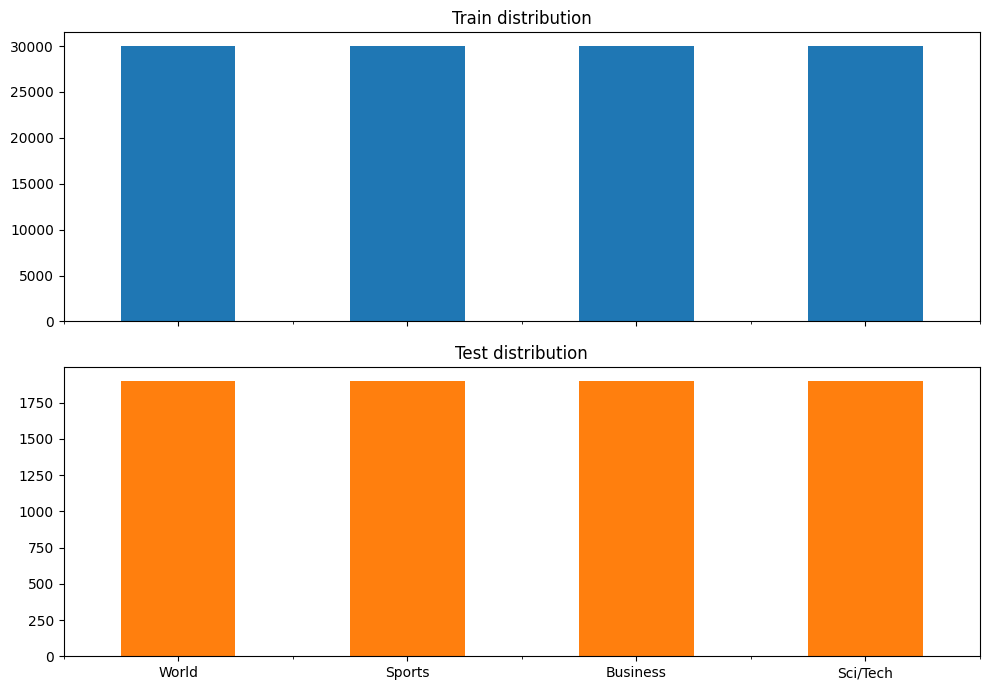

In [7]:
import matplotlib.pyplot as plt

distribution = pd.DataFrame({
    "train": train_df["label"].value_counts().sort_index(),
    "test": test_df["label"].value_counts().sort_index()
})

distribution.index = class_names

distribution["train_pct"] = (
    distribution["train"] / len(train_df) * 100
)

distribution["test_pct"] = (
    distribution["test"] / len(test_df) * 100
)

display(distribution.round(2))

distribution[["train", "test"]].plot(
    kind="bar",
    subplots=True,
    figsize=(10, 7),
    rot=0,
    legend=False,
    title=["Train distribution", "Test distribution"]
)

plt.tight_layout()
plt.show()


In [8]:
for name, df in [
    ("Train", train_df),
    ("Test", test_df)
]:
    missing_text = df["text"].isna().sum()

    empty_text = (
        df["text"]
        .fillna("")
        .str.strip()
        .eq("")
        .sum()
    )

    missing_label = df["label"].isna().sum()

    invalid_label = (
        ~df["label"].isin(range(len(class_names)))
    ).sum()

    print(f"\n{name}")
    print("Missing text:", missing_text)
    print("Empty text:", empty_text)
    print("Missing label:", missing_label)
    print("Invalid label:", invalid_label)



Train
Missing text: 0
Empty text: 0
Missing label: 0
Invalid label: 0

Test
Missing text: 0
Empty text: 0
Missing label: 0
Invalid label: 0


In [9]:
import re

def normalize_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

train_df["normalized_text"] = (
    train_df["text"]
    .fillna("")
    .map(normalize_text)
)

test_df["normalized_text"] = (
    test_df["text"]
    .fillna("")
    .map(normalize_text)
)

train_duplicates = train_df["normalized_text"].duplicated().sum()
test_duplicates = test_df["normalized_text"].duplicated().sum()

train_texts = set(train_df["normalized_text"])
test_texts = set(test_df["normalized_text"])

common_texts = train_texts & test_texts
common_texts.discard("")

test_overlap_rows = (
    test_df["normalized_text"].isin(common_texts).sum()
)

print("Train duplicate rows:", train_duplicates)
print("Test duplicate rows:", test_duplicates)
print("Unique train/test overlaps:", len(common_texts))
print("Overlapping test rows:", test_overlap_rows)

print(
    "Test overlap rate:",
    f"{test_overlap_rows / len(test_df):.2%}"
)


Train duplicate rows: 151
Test duplicate rows: 0
Unique train/test overlaps: 10
Overlapping test rows: 10
Test overlap rate: 0.13%


Статистика по количеству слов:


count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
50%          37.000000
90%          48.000000
95%          53.000000
99%          70.000000
max         177.000000
Name: word_length, dtype: float64


Длины текстов по классам:


,mean,median,min,max
class_name,,,,
Business,37.5,37.0,8,134
Sci/Tech,37.2,36.0,8,177
Sports,37.8,37.0,8,151
World,38.9,39.0,11,145


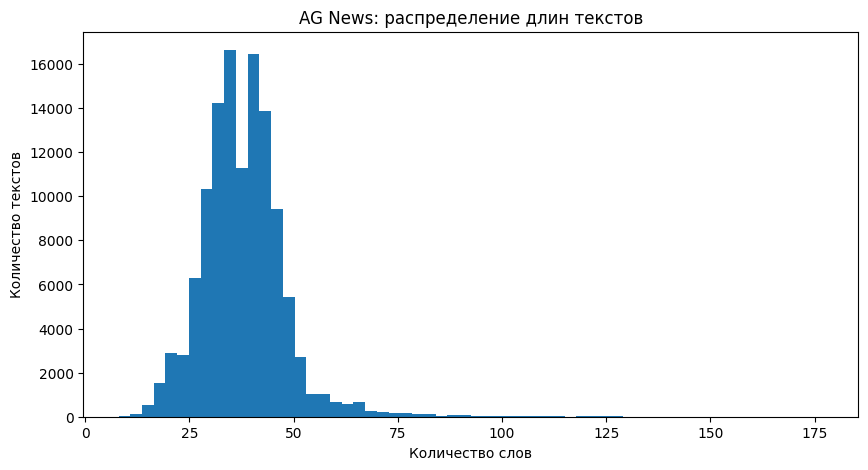

In [10]:
for df in [train_df, test_df]:
    df["char_length"] = df["text"].str.len()
    df["word_length"] = df["text"].str.split().str.len()

print("Статистика по количеству слов:")

display(
    train_df["word_length"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

print("\nДлины текстов по классам:")

display(
    train_df.groupby("class_name")["word_length"]
    .agg(["mean", "median", "min", "max"])
    .round(1)
)

plt.figure(figsize=(10, 5))
plt.hist(
    train_df["word_length"],
    bins=60
)
plt.xlabel("Количество слов")
plt.ylabel("Количество текстов")
plt.title("AG News: распределение длин текстов")
plt.show()


In [11]:

quality_checks = {
    "Очень короткие тексты (<5 слов)": (
        train_df["word_length"] < 5
    ).sum(),

    "Тексты с обратным слешем": (
        train_df["text"].str.contains(
            r"\\", regex=True, na=False
        )
    ).sum(),

    "HTML-подобные сущности": (
        train_df["text"].str.contains(
            r"&(?:[A-Za-z]+|#\d+);",
            regex=True,
            na=False
        )
    ).sum(),

    "Фрагменты вида #36;": (
        train_df["text"].str.contains(
            r"#\d+;",
            regex=True,
            na=False
        )
    ).sum()
}

quality_df = pd.DataFrame({
    "count": quality_checks,
})

quality_df["percentage"] = (
    quality_df["count"] / len(train_df) * 100
)

display(quality_df.round(2))


,count,percentage
Очень короткие тексты (<5 слов),0,0.00
Тексты с обратным слешем,13146,10.96
HTML-подобные сущности,5243,4.37
Фрагменты вида #36;,31357,26.13


In [14]:

import numpy as np
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

token_sample = train_df.sample(
    n=5000,
    random_state=SEED
)

encoded = tokenizer(
    token_sample["text"].tolist(),
    add_special_tokens=True,
    padding=False,
    truncation=False,
    return_length=True
)

token_lengths = np.array(encoded["length"])

print("Статистика длин в токенах:")
print("Mean:", token_lengths.mean())
print("Median:", np.median(token_lengths))
print("P90:", np.percentile(token_lengths, 90))
print("P95:", np.percentile(token_lengths, 95))
print("P99:", np.percentile(token_lengths, 99))
print("Maximum:", token_lengths.max())

print("\nДоля длиннее выбранного лимита:")
for limit in [64, 128, 256]:
    pct = 100 * np.mean(token_lengths > limit)
    print(f"{limit} tokens: {pct:.2f}%")


Статистика длин в токенах:
Mean: 53.1526
Median: 50.0
P90: 70.0
P95: 81.0
P99: 121.0
Maximum: 348

Доля длиннее выбранного лимита:
64 tokens: 14.76%
128 tokens: 0.80%
256 tokens: 0.06%


In [15]:
unk_id = tokenizer.unk_token_id

unk_counts = np.array([
    sum(token_id == unk_id for token_id in ids)
    for ids in encoded["input_ids"]
])

print("Текстов с [UNK]:", np.sum(unk_counts > 0))
print(
    "Доля текстов с [UNK]:",
    f"{np.mean(unk_counts > 0):.2%}"
)
print("Общее число [UNK]:", unk_counts.sum())


Текстов с [UNK]: 0
Доля текстов с [UNK]: 0.00%
Общее число [UNK]: 0


In [17]:
def normalize_text(text):
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

train_df["normalized_text"] = (
    train_df["text"].fillna("").map(normalize_text)
)

test_df["normalized_text"] = (
    test_df["text"].fillna("").map(normalize_text)
)

label_counts_per_text = (
    train_df.groupby("normalized_text")["label"].nunique()
)

conflicting_texts = set(
    label_counts_per_text[
        label_counts_per_text > 1
    ].index
)

print("Текстов с конфликтующими метками:", len(conflicting_texts))


Текстов с конфликтующими метками: 22


In [18]:
from sklearn.model_selection import train_test_split

valid_rows = (
    train_df["text"].notna()
    & train_df["text"].str.strip().ne("")
    & train_df["label"].isin(range(len(class_names)))
)

train_clean = train_df.loc[
    valid_rows
    & ~train_df["normalized_text"].isin(conflicting_texts)
].copy()

train_clean = train_clean.drop_duplicates(
    subset="normalized_text"
)

print("Осталось после очистки:", len(train_clean))

subset = (
    train_clean
    .groupby("label", group_keys=False)
    .sample(n=5000, random_state=SEED)
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)

train_part, val_part = train_test_split(
    subset,
    test_size=0.1,
    random_state=SEED,
    stratify=subset["label"]
)

train_part = train_part.reset_index(drop=True)
val_part = val_part.reset_index(drop=True)

print("Train:", len(train_part))
print("Validation:", len(val_part))
print("Official test:", len(test_df))


Осталось после очистки: 119827
Train: 18000
Validation: 2000
Official test: 7600


In [19]:
train_keys = set(train_part["normalized_text"])
val_keys = set(val_part["normalized_text"])
test_keys = set(test_df["normalized_text"])

assert train_keys.isdisjoint(val_keys)

print("Train/validation overlap:", len(train_keys & val_keys))
print("Train/test overlap:", len(train_keys & test_keys))
print("Validation/test overlap:", len(val_keys & test_keys))

print("\nРаспределение train:")
print(train_part["class_name"].value_counts())

print("\nРаспределение validation:")
print(val_part["class_name"].value_counts())


Train/validation overlap: 0
Train/test overlap: 2
Validation/test overlap: 1

Распределение train:
class_name
Sports      4500
World       4500
Business    4500
Sci/Tech    4500
Name: count, dtype: int64

Распределение validation:
class_name
Business    500
Sci/Tech    500
Sports      500
World       500
Name: count, dtype: int64


In [20]:
used_texts = (
    set(train_part["normalized_text"])
    | set(val_part["normalized_text"])
)

test_clean = test_df[
    ~test_df["normalized_text"].isin(used_texts)
].copy().reset_index(drop=True)

print("Original test size:", len(test_df))
print("Clean test size:", len(test_clean))
print("Removed:", len(test_df) - len(test_clean))

assert set(test_clean["normalized_text"]).isdisjoint(
    used_texts
)

print("Data leakage check passed!")


Original test size: 7600
Clean test size: 7597
Removed: 3
Data leakage check passed!


In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tfidf = TfidfVectorizer(
    max_features=40000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    stop_words="english",
    sublinear_tf=True,
    dtype=np.float32
)

X_train = tfidf.fit_transform(train_part["text"])
X_val = tfidf.transform(val_part["text"])

y_train = train_part["label"].to_numpy()
y_val = val_part["label"].to_numpy()

print("Train TF-IDF shape:", X_train.shape)
print("Validation TF-IDF shape:", X_val.shape)

baseline_model = LogisticRegression(
    max_iter=400
)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("Macro F1:", f1_score(y_val, y_pred, average="macro"))


Train TF-IDF shape: (18000, 40000)
Validation TF-IDF shape: (2000, 40000)
Accuracy: 0.909
Macro F1: 0.9084567078202423


In [24]:
rng = np.random.default_rng(SEED)

y_shuffled = rng.permutation(y_train)

shuffled_model = LogisticRegression(
    max_iter=400
)

shuffled_model.fit(X_train, y_shuffled)

shuffled_pred = shuffled_model.predict(X_val)

results.loc["Shuffled labels"] = calculate_metrics(
    y_val, shuffled_pred
)

display(results.round(4))


,Accuracy,Precision,Recall,F1 macro
Most frequent,0.2500,0.0625,0.2500,0.1000
Random,0.2445,0.2444,0.2445,0.2443
TF-IDF + LR,0.9090,0.9084,0.9090,0.9085
Shuffled labels,0.2565,0.2562,0.2565,0.2560


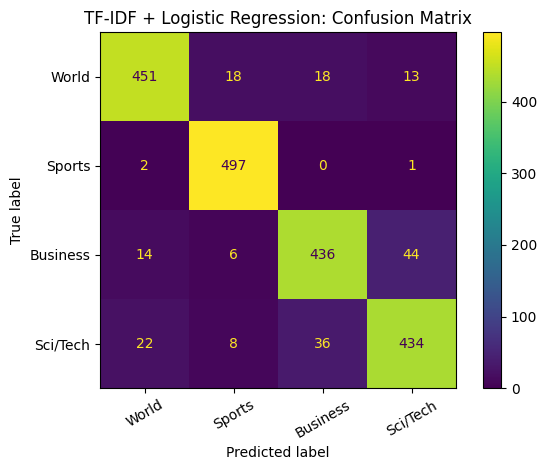

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=list(range(len(class_names))),
    display_labels=class_names,
    xticks_rotation=30
)

plt.title("TF-IDF + Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()


In [26]:
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModel,
    DataCollatorWithPadding
)

SEED = 42
MODEL_NAME = "distilbert/distilbert-base-uncased"

MAX_LENGTH = 128
BATCH_SIZE = 16
NUM_CLASSES = 4

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(SEED)

print("Device:", device)
print("Train samples:", len(train_part))
print("Validation samples:", len(val_part))

Device: cuda
Train samples: 18000
Validation samples: 2000


In [27]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    train_part["text"].tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

val_encodings = tokenizer(
    val_part["text"].tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

print("Train:", len(train_encodings["input_ids"]))
print("Validation:", len(val_encodings["input_ids"]))

print("\nПервый текст:")
print(train_part["text"].iloc[0][:300])

print("\nЕго токены:")
print(
    tokenizer.convert_ids_to_tokens(
        train_encodings["input_ids"][0]
    )
)

print("\nAttention mask:")
print(train_encodings["attention_mask"][0])


Train: 18000
Validation: 2000

Первый текст:
HENRY SHOWS HE IS STILL KING Thierry Henry answered his critics in style as he combined with Robert Pires to haul Arsenal out of their slump. Henrys recent form had been called into question by Match of the Day pundit Alan Hansen only 

Его токены:
['[CLS]', 'henry', 'shows', 'he', 'is', 'still', 'king', 'thierry', 'henry', 'answered', 'his', 'critics', 'in', 'style', 'as', 'he', 'combined', 'with', 'robert', 'pi', '##res', 'to', 'haul', 'arsenal', 'out', 'of', 'their', 'slump', '.', 'henry', '##s', 'recent', 'form', 'had', 'been', 'called', 'into', 'question', 'by', 'match', 'of', 'the', 'day', 'pun', '##dit', 'alan', 'hansen', 'only', '[SEP]']

Attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [29]:
class NewsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "labels": int(self.labels[idx])
        }


train_dataset = NewsDataset(
    train_encodings,
    train_part["label"]
)

val_dataset = NewsDataset(
    val_encodings,
    val_part["label"]
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))

print("\nПервый пример:")
print(train_dataset[0])


Train dataset: 18000
Validation dataset: 2000

Первый пример:
{'input_ids': [101, 2888, 3065, 2002, 2003, 2145, 2332, 26413, 2888, 4660, 2010, 4401, 1999, 2806, 2004, 2002, 4117, 2007, 2728, 14255, 6072, 2000, 14655, 9433, 2041, 1997, 2037, 28702, 1012, 2888, 2015, 3522, 2433, 2018, 2042, 2170, 2046, 3160, 2011, 2674, 1997, 1996, 2154, 26136, 23194, 5070, 13328, 2069, 102], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels': 1}


In [30]:
collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    pad_to_multiple_of=8,
    return_tensors="pt"
)

def make_train_loader(seed=SEED):
    generator = torch.Generator().manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=collator,
        generator=generator,
        num_workers=0,
        pin_memory=(device.type == "cuda")
    )


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

train_loader = make_train_loader()

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))


Train batches: 1125
Validation batches: 125


In [31]:
batch = next(iter(val_loader))

print("Batch keys:", batch.keys())

for key, value in batch.items():
    print(key, value.shape, value.dtype)

print("\nПервый пример после padding:")
print("Input IDs:", batch["input_ids"][0])
print("Attention mask:", batch["attention_mask"][0])
print("Label:", batch["labels"][0].item())

assert batch["input_ids"].shape[0] == BATCH_SIZE
assert batch["input_ids"].shape[1] <= MAX_LENGTH
assert batch["input_ids"].shape == batch["attention_mask"].shape
assert batch["labels"].dtype == torch.long

print("\nBatch test passed!")


Batch keys: KeysView({'input_ids': tensor([[  101,  2190,  4004,  ...,  4436,  1012,   102],
        [  101,  3021,  6733,  ...,     0,     0,     0],
        [  101,  2655,  2005,  ...,     0,     0,     0],
        ...,
        [  101,  6373, 10457,  ...,     0,     0,     0],
        [  101,  2900, 27785,  ...,     0,     0,     0],
        [  101,  2022, 12190,  ...,     0,     0,     0]]), 'attention_mask': tensor([[1, 1, 1,  ..., 1, 1, 1],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]]), 'labels': tensor([2, 3, 3, 1, 2, 2, 2, 1, 3, 0, 3, 0, 2, 3, 0, 0])})
input_ids torch.Size([16, 72]) torch.int64
attention_mask torch.Size([16, 72]) torch.int64
labels torch.Size([16]) torch.int64

Первый пример после padding:
Input IDs: tensor([  101,  2190,  4004,  6813, 14345,  1996,  2047,  9706,  2213,  2546,
         5002,  1997,  1996,  2190,  4004,  6813, 

In [32]:
def mean_pooling(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(
        dtype=last_hidden_state.dtype
    )

    summed = (last_hidden_state * mask).sum(dim=1)

    counts = mask.sum(dim=1).clamp(min=1)

    return summed / counts


def cls_pooling(last_hidden_state):
    return last_hidden_state[:, 0, :]


In [33]:
class TextClassifier(nn.Module):
    def __init__(self, pooling="mean", num_classes=4):
        super().__init__()

        if pooling not in ("mean", "cls"):
            raise ValueError("pooling must be 'mean' or 'cls'")

        self.pooling = pooling

        self.encoder = AutoModel.from_pretrained(MODEL_NAME)

        hidden_size = self.encoder.config.dim

        self.dropout = nn.Dropout(0.1)

        self.classifier = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        hidden = outputs.last_hidden_state

        if self.pooling == "mean":
            pooled = mean_pooling(hidden, attention_mask)
        else:
            pooled = cls_pooling(hidden)

        pooled = self.dropout(pooled)

        logits = self.classifier(pooled)

        return logits


In [34]:
torch.manual_seed(SEED)

model = TextClassifier(
    pooling="mean",
    num_classes=NUM_CLASSES
)

model = model.to(device)

print("Model device:", next(model.parameters()).device)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Model device: cuda:0
Total parameters: 66,365,956
Trainable parameters: 66,365,956


In [35]:
batch_gpu = {
    key: value.to(device)
    for key, value in batch.items()
}

model.eval()

with torch.inference_mode():
    logits = model(
        input_ids=batch_gpu["input_ids"],
        attention_mask=batch_gpu["attention_mask"]
    )

print("Logits shape:", logits.shape)
print("Labels shape:", batch_gpu["labels"].shape)

print("\nЛогиты первого текста:")
print(logits[0].cpu())

print("\nПредсказанный класс:")
predicted_class = logits.argmax(dim=1)[0].item()
print(class_names[predicted_class])

assert logits.shape == (BATCH_SIZE, NUM_CLASSES)

print("\nForward pass successful!")


Logits shape: torch.Size([16, 4])
Labels shape: torch.Size([16])

Логиты первого текста:
tensor([ 0.0095,  0.1391,  0.0401, -0.2076])

Предсказанный класс:
Sports

Forward pass successful!


In [36]:
criterion = nn.CrossEntropyLoss()

model.eval()

with torch.inference_mode():
    model.pooling = "mean"
    logits_mean = model(
        batch_gpu["input_ids"],
        batch_gpu["attention_mask"]
    )

    model.pooling = "cls"
    logits_cls = model(
        batch_gpu["input_ids"],
        batch_gpu["attention_mask"]
    )

    loss_mean = criterion(
        logits_mean, batch_gpu["labels"]
    )

    loss_cls = criterion(
        logits_cls, batch_gpu["labels"]
    )

model.pooling = "mean"

print("Mean logits shape:", logits_mean.shape)
print("CLS logits shape:", logits_cls.shape)

print("Mean initial loss:", loss_mean.item())
print("CLS initial loss:", loss_cls.item())

assert torch.isfinite(loss_mean)
assert torch.isfinite(loss_cls)

if device.type == "cuda":
    print(
        "GPU allocated memory:",
        f"{torch.cuda.memory_allocated() / 1024**3:.2f} GiB"
    )

print("\nBoth pooling strategies work!")


Mean logits shape: torch.Size([16, 4])
CLS logits shape: torch.Size([16, 4])
Mean initial loss: 1.4082691669464111
CLS initial loss: 1.3655487298965454
GPU allocated memory: 0.27 GiB

Both pooling strategies work!


In [37]:

import gc
import time
import random
from pathlib import Path
from contextlib import nullcontext

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from transformers import get_linear_schedule_with_warmup

SEED = 42
NUM_EPOCHS = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

# Освобождаем модель, созданную при проверке архитектуры
if "model" in globals():
    del model

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()
    USE_AMP = True
    AMP_DTYPE = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )
else:
    USE_AMP = False
    AMP_DTYPE = torch.float32

USE_FP16_SCALER = (
    USE_AMP and AMP_DTYPE == torch.float16
)

def amp_context():
    if USE_AMP:
        return torch.autocast(
            device_type="cuda",
            dtype=AMP_DTYPE
        )
    return nullcontext()

print("Device:", device)
print("Mixed precision:", USE_AMP)
print("AMP dtype:", AMP_DTYPE)
print("Epochs:", NUM_EPOCHS)


Device: cuda
Mixed precision: True
AMP dtype: torch.bfloat16
Epochs: 3


In [38]:
@torch.inference_mode()
def evaluate_model(model, data_loader):
    model.eval()

    criterion = torch.nn.CrossEntropyLoss()

    total_loss = 0.0
    total_examples = 0

    all_predictions = []
    all_labels = []

    for batch in tqdm(
        data_loader,
        desc="Validation",
        leave=False
    ):
        batch = {
            k: v.to(device, non_blocking=True)
            for k, v in batch.items()
        }

        with amp_context():
            logits = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            loss = criterion(logits, batch["labels"])

        predictions = logits.argmax(dim=-1)

        batch_size = batch["labels"].size(0)

        total_loss += loss.item() * batch_size
        total_examples += batch_size

        all_predictions.extend(
            predictions.cpu().tolist()
        )
        all_labels.extend(
            batch["labels"].cpu().tolist()
        )

    return {
        "loss": total_loss / total_examples,
        "accuracy": accuracy_score(
            all_labels, all_predictions
        ),
        "precision": precision_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        ),
        "recall": recall_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        ),
        "f1": f1_score(
            all_labels,
            all_predictions,
            average="macro",
            zero_division=0
        )
    }


In [39]:
def train_one_epoch(
    model,
    train_loader,
    optimizer,
    scheduler,
    scaler,
    epoch
):
    model.train()

    criterion = torch.nn.CrossEntropyLoss()

    total_loss = 0.0
    total_examples = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{NUM_EPOCHS}"
    )

    start_time = time.perf_counter()

    for step, batch in enumerate(progress_bar, start=1):

        batch = {
            k: v.to(device, non_blocking=True)
            for k, v in batch.items()
        }

        optimizer.zero_grad(set_to_none=True)

        with amp_context():
            logits = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )

            loss = criterion(
                logits,
                batch["labels"]
            )

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            MAX_GRAD_NORM
        )

        old_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()

        if (
            not USE_FP16_SCALER
            or scaler.get_scale() >= old_scale
        ):
            scheduler.step()

        batch_size = batch["labels"].size(0)

        total_loss += loss.item() * batch_size
        total_examples += batch_size

        if step % 20 == 0:
            progress_bar.set_postfix(
                loss=f"{total_loss / total_examples:.4f}"
            )

        if epoch == 1 and step == 100:
            if device.type == "cuda":
                torch.cuda.synchronize()

            elapsed = time.perf_counter() - start_time

            print(
                f"\n100 batches in {elapsed:.1f} sec"
            )
            print(
                f"Average: {elapsed / 100:.3f} sec/batch"
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    return {
        "loss": total_loss / total_examples,
        "time": epoch_time
    }


In [40]:
def run_experiment(pooling_type):
    print(f"\n{'=' * 55}")
    print(f"Starting experiment: {pooling_type}")
    print(f"{'=' * 55}")

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)
        torch.cuda.reset_peak_memory_stats()

    model = TextClassifier(
        pooling=pooling_type,
        num_classes=NUM_CLASSES
    ).to(device)

    loader = make_train_loader(seed=SEED)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    total_steps = len(loader) * NUM_EPOCHS
    warmup_steps = int(total_steps * 0.1)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=USE_FP16_SCALER
    )

    history = []
    best_f1 = -1.0
    best_metrics = None
    best_epoch = None

    checkpoint_path = (
        CHECKPOINT_DIR / f"distilbert_{pooling_type}.pt"
    )

    experiment_start = time.perf_counter()

    for epoch in range(1, NUM_EPOCHS + 1):

        train_stats = train_one_epoch(
            model,
            loader,
            optimizer,
            scheduler,
            scaler,
            epoch
        )

        val_stats = evaluate_model(
            model,
            val_loader
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_stats["loss"],
            "val_loss": val_stats["loss"],
            "val_accuracy": val_stats["accuracy"],
            "val_precision": val_stats["precision"],
            "val_recall": val_stats["recall"],
            "val_f1": val_stats["f1"],
            "train_time_sec": train_stats["time"]
        })

        print(
            f"\nEpoch {epoch}: "
            f"train_loss={train_stats['loss']:.4f}, "
            f"val_loss={val_stats['loss']:.4f}, "
            f"val_f1={val_stats['f1']:.4f}"
        )

        if val_stats["f1"] > best_f1:
            best_f1 = val_stats["f1"]
            best_metrics = val_stats.copy()
            best_epoch = epoch

            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "pooling": pooling_type,
                "val_metrics": val_stats
            }, checkpoint_path)

            print("Best model saved!")

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - experiment_start

    peak_memory_gib = (
        torch.cuda.max_memory_allocated() / 1024**3
        if device.type == "cuda"
        else None
    )

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        CHECKPOINT_DIR / f"history_{pooling_type}.csv",
        index=False
    )

    print(f"\nBest epoch: {best_epoch}")
    print(f"Best validation F1: {best_f1:.4f}")
    print(f"Total time: {total_time / 60:.1f} minutes")

    if peak_memory_gib is not None:
        print(f"Peak VRAM: {peak_memory_gib:.2f} GiB")

    result = {
        "pooling": pooling_type,
        "history": history_df,
        "best_metrics": best_metrics,
        "best_epoch": best_epoch,
        "total_time": total_time,
        "peak_vram": peak_memory_gib,
        "checkpoint": str(checkpoint_path)
    }

    del model, optimizer, scheduler, scaler, loader
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return result


In [41]:
mean_result = run_experiment("mean")

display(mean_result["history"])



Starting experiment: mean


Epoch 1/3:   0%|          | 0/1125 [00:00<?, ?it/s]


100 batches in 5.8 sec
Average: 0.058 sec/batch


Validation:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 1: train_loss=0.4068, val_loss=0.2477, val_f1=0.9174
Best model saved!


Epoch 2/3:   0%|          | 0/1125 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch 3/3:   0%|          | 0/1125 [00:00<?, ?it/s]

Validation:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 3: train_loss=0.1119, val_loss=0.2675, val_f1=0.9314
Best model saved!

Best epoch: 3
Best validation F1: 0.9314
Total time: 3.1 minutes
Peak VRAM: 1.29 GiB


,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,train_time_sec
0,1,0.406827,0.247749,0.9175,0.917506,0.9175,0.917362,60.728949
1,2,0.182072,0.235407,0.9270,0.927258,0.9270,0.926891,60.093324
2,3,0.111921,0.267450,0.9315,0.931457,0.9315,0.931350,60.184932


In [42]:
cls_result = run_experiment("cls")

display(cls_result["history"])



Starting experiment: cls


Epoch 1/3:   0%|          | 0/1125 [00:00<?, ?it/s]


100 batches in 5.6 sec
Average: 0.056 sec/batch


Validation:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 1: train_loss=0.3942, val_loss=0.2268, val_f1=0.9245
Best model saved!


Epoch 2/3:   0%|          | 0/1125 [00:00<?, ?it/s]

... (2 outputs left out)

Epoch 3/3:   0%|          | 0/1125 [00:00<?, ?it/s]

Validation:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 3: train_loss=0.1051, val_loss=0.2673, val_f1=0.9268

Best epoch: 2
Best validation F1: 0.9287
Total time: 3.1 minutes
Peak VRAM: 1.29 GiB


,epoch,train_loss,val_loss,val_accuracy,val_precision,val_recall,val_f1,train_time_sec
0,1,0.394236,0.226826,0.9245,0.924555,0.9245,0.924496,60.383161
1,2,0.174097,0.236594,0.9290,0.929050,0.9290,0.928740,60.001604
2,3,0.105097,0.267252,0.9270,0.926824,0.9270,0.926803,60.199368


In [43]:
comparison = pd.DataFrame({
    "Mean pooling": {
        "Accuracy": mean_result["best_metrics"]["accuracy"],
        "Precision": mean_result["best_metrics"]["precision"],
        "Recall": mean_result["best_metrics"]["recall"],
        "Macro F1": mean_result["best_metrics"]["f1"],
        "Best epoch": mean_result["best_epoch"],
        "Training + validation (min)": mean_result["total_time"] / 60
    },
    "CLS pooling": {
        "Accuracy": cls_result["best_metrics"]["accuracy"],
        "Precision": cls_result["best_metrics"]["precision"],
        "Recall": cls_result["best_metrics"]["recall"],
        "Macro F1": cls_result["best_metrics"]["f1"],
        "Best epoch": cls_result["best_epoch"],
        "Training + validation (min)": cls_result["total_time"] / 60
    }
}).T

display(comparison.round(4))

comparison.to_csv(
    CHECKPOINT_DIR / "comparison_validation.csv"
)


,Accuracy,Precision,Recall,Macro F1,Best epoch,Training + validation (min)
Mean pooling,0.9315,0.9315,0.9315,0.9314,3.0,3.0976
CLS pooling,0.9290,0.9290,0.9290,0.9287,2.0,3.0811


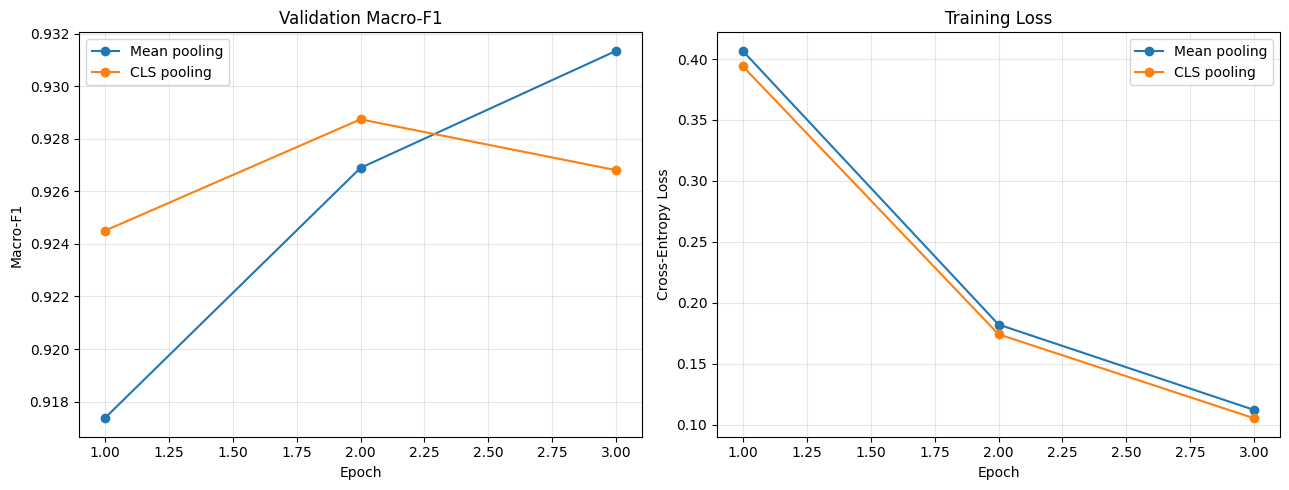

In [44]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for result, label in [
    (mean_result, "Mean pooling"),
    (cls_result, "CLS pooling")
]:
    history = result["history"]

    axes[0].plot(
        history["epoch"],
        history["val_f1"],
        marker="o",
        label=label
    )

    axes[1].plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label=label
    )

axes[0].set_title("Validation Macro-F1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Macro-F1")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [45]:
used_texts = (
    set(train_part["normalized_text"])
    | set(val_part["normalized_text"])
)

assert set(test_clean["normalized_text"]).isdisjoint(
    used_texts
)

test_encodings = tokenizer(
    test_clean["text"].tolist(),
    truncation=True,
    max_length=MAX_LENGTH,
    padding=False
)

test_dataset = NewsDataset(
    test_encodings,
    test_clean["label"]
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collator,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Test examples:", len(test_dataset))
print("Test batches:", len(test_loader))


Test examples: 7597
Test batches: 475


In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

@torch.inference_mode()
def test_checkpoint(pooling_type):
    model = TextClassifier(
        pooling=pooling_type,
        num_classes=NUM_CLASSES
    )

    checkpoint_path = (
        CHECKPOINT_DIR / f"distilbert_{pooling_type}.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    y_true = []
    y_pred = []

    for batch in tqdm(
        test_loader,
        desc=f"Testing {pooling_type}"
    ):
        labels = batch["labels"].tolist()

        inputs = {
            k: v.to(device)
            for k, v in batch.items()
            if k != "labels"
        }

        with amp_context():
            logits = model(**inputs)

        predictions = logits.argmax(dim=-1)

        y_true.extend(labels)
        y_pred.extend(predictions.cpu().tolist())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="macro"
        ),
        "Recall": recall_score(
            y_true, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro"
        )
    }

    del model
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return {
        "metrics": metrics,
        "y_true": np.array(y_true),
        "y_pred": np.array(y_pred),
        "epoch": checkpoint["epoch"]
    }


mean_test = test_checkpoint("mean")
cls_test = test_checkpoint("cls")

print("Both models evaluated!")


Testing mean:   0%|          | 0/475 [00:00<?, ?it/s]

Testing cls:   0%|          | 0/475 [00:00<?, ?it/s]

Both models evaluated!


In [47]:
X_test_tfidf = tfidf.transform(test_clean["text"])

tfidf_pred = baseline_model.predict(X_test_tfidf)
y_test = test_clean["label"].to_numpy()

tfidf_test_metrics = {
    "Accuracy": accuracy_score(y_test, tfidf_pred),
    "Precision": precision_score(
        y_test, tfidf_pred, average="macro"
    ),
    "Recall": recall_score(
        y_test, tfidf_pred, average="macro"
    ),
    "Macro F1": f1_score(
        y_test, tfidf_pred, average="macro"
    )
}

test_comparison = pd.DataFrame({
    "TF-IDF + LR": tfidf_test_metrics,
    "DistilBERT Mean": mean_test["metrics"],
    "DistilBERT CLS": cls_test["metrics"]
}).T

display(test_comparison.round(4))

test_comparison.to_csv(
    CHECKPOINT_DIR / "comparison_test.csv"
)

winner = test_comparison["Macro F1"].idxmax()

print("\nBest model on test:", winner)


,Accuracy,Precision,Recall,Macro F1
TF-IDF + LR,0.9025,0.9020,0.9025,0.9021
DistilBERT Mean,0.9294,0.9295,0.9295,0.9294
DistilBERT CLS,0.9258,0.9259,0.9258,0.9257



Best model on test: DistilBERT Mean


In [48]:

y_true = mean_test["y_true"]

assert np.array_equal(
    y_true,
    cls_test["y_true"]
)

mean_correct = mean_test["y_pred"] == y_true
cls_correct = cls_test["y_pred"] == y_true

both_correct = np.sum(mean_correct & cls_correct)
both_wrong = np.sum(~mean_correct & ~cls_correct)

mean_only = np.sum(mean_correct & ~cls_correct)
cls_only = np.sum(~mean_correct & cls_correct)

print("Both correct:", both_correct)
print("Both wrong:", both_wrong)
print("Only Mean correct:", mean_only)
print("Only CLS correct:", cls_only)
print()
print("Net advantage of Mean:", mean_only - cls_only)


Both correct: 6964
Both wrong: 467
Only Mean correct: 97
Only CLS correct: 69

Net advantage of Mean: 28
